# Phase 3: Machine Learning Model Design (LEAN FEATURE SET — v2)
## Airline Loyalty Disengagement Project

**Author:** Sora | **Date:** May 2026

**Why this v2 notebook exists:** The v1 notebook used a 22-feature panel that turned out to suffer
from severe multicollinearity. A correlation audit revealed 24 pairs with |r| >= 0.7 and four pairs
that were essentially duplicate columns (r = 1.00). This degraded both LR (bizarre coefficient signs)
and LightGBM (the EDA's strongest discriminators were buried under compound features). This v2 uses
a curated lean feature set with zero pairs at |r| >= 0.7.

**Lean feature set: 7 numeric + 6 categorical = 13 features total.**

Numeric:
- `rec_months_since_flight` — recency (EDA: 5.5x discrimination at the tail)
- `freq_months_active_6mo` — engagement consistency (EDA: 9x discrimination, the strongest single signal)
- `freq_flights_per_active_month` — intensity when active (orthogonal to months_active)
- `trend_flights_diff` — trajectory (positive = accelerating, negative = declining)
- `mon_redeem_ratio` — program engagement (redemptions / accumulations)
- `mon_clv_asof_proxy` — historical scale (total points accumulated through T)
- `demo_tenure_months` — lifecycle stage

Categorical (kept all six, they don't contribute to the multicollinearity problem):
- Gender, Education, Salary_Band, Marital Status, Loyalty Card, Province

**Inputs:** `labeled_features_lean.csv` (22,759 rows, 16 columns)

**Outputs (will be saved to your output directory):**
- Same metric/prediction/SHAP/segmentation outputs as before


## 1. Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                              precision_recall_curve, roc_curve, f1_score,
                              silhouette_score, davies_bouldin_score)
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb
import optuna
import shap

DATA_DIR = "../data/processed"
OUT_DIR  = "../data/processed"

np.random.seed(42)
optuna.logging.set_verbosity(optuna.logging.WARNING)

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
print("Libraries imported OK.")


Libraries imported OK.


## 2. Load lean feature table and split temporally

In [2]:
df = pd.read_csv(f"{DATA_DIR}/labeled_features_lean.csv", parse_dates=['as_of_date'])

CAT_COLS = ['Gender','Education','Salary_Band','Marital Status','Loyalty Card','Province']
ID_COLS  = ['Loyalty Number','as_of_date','churned']
NUM_COLS = [c for c in df.columns if c not in CAT_COLS + ID_COLS]

print(f"Total rows: {len(df):,}")
print(f"Numeric features ({len(NUM_COLS)}): {NUM_COLS}")
print(f"Categorical features ({len(CAT_COLS)}): {CAT_COLS}")

# Confirm correlation structure is clean
print("\nCorrelation matrix (numeric features):")
print(df[NUM_COLS].corr().round(2).to_string())

train = df[df['as_of_date'] == pd.Timestamp('2018-01-01')].copy()
test  = df[df['as_of_date'] == pd.Timestamp('2018-07-01')].copy()
print(f"\nTrain: {len(train):,} rows, {train['churned'].sum()} churners ({train['churned'].mean()*100:.2f}%)")
print(f"Test:  {len(test):,} rows, {test['churned'].sum()} churners ({test['churned'].mean()*100:.2f}%)")


Total rows: 22,759
Numeric features (7): ['rec_months_since_flight', 'freq_months_active_6mo', 'freq_flights_per_active_month', 'trend_flights_diff', 'mon_redeem_ratio', 'mon_clv_asof_proxy', 'demo_tenure_months']
Categorical features (6): ['Gender', 'Education', 'Salary_Band', 'Marital Status', 'Loyalty Card', 'Province']

Correlation matrix (numeric features):
                               rec_months_since_flight  freq_months_active_6mo  freq_flights_per_active_month  trend_flights_diff  mon_redeem_ratio  mon_clv_asof_proxy  demo_tenure_months
rec_months_since_flight                           1.00                   -0.51                          -0.08               -0.42              0.08               -0.21                0.00
freq_months_active_6mo                           -0.51                    1.00                           0.01                0.01             -0.12                0.37                0.01
freq_flights_per_active_month                    -0.08                 

## 3. Evaluation helper

In [3]:
def metrics(y_true, y_proba, name=""):
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)
    roc_auc = roc_auc_score(y_true, y_proba)
    pr_auc  = average_precision_score(y_true, y_proba)
    brier   = brier_score_loss(y_true, y_proba)
    n = len(y_proba)
    order = np.argsort(-y_proba)
    top_10 = order[:max(1, n // 10)]
    top_20 = order[:max(1, n // 5)]
    base = y_true.mean()
    lift_10 = y_true[top_10].mean() / base if base > 0 else 0
    lift_20 = y_true[top_20].mean() / base if base > 0 else 0
    prec, rec, thr = precision_recall_curve(y_true, y_proba)
    f1_scores = 2 * prec * rec / (prec + rec + 1e-12)
    best_idx = int(np.argmax(f1_scores))
    best_f1  = float(f1_scores[best_idx])
    best_thr = float(thr[best_idx-1]) if best_idx > 0 else 0.5
    print(f"\n--- {name} ---")
    print(f"  ROC-AUC:        {roc_auc:.4f}")
    print(f"  PR-AUC:         {pr_auc:.4f}   (baseline = {base:.4f})")
    print(f"  Brier:          {brier:.5f}")
    print(f"  Lift @ top 10%: {lift_10:.2f}x")
    print(f"  Lift @ top 20%: {lift_20:.2f}x")
    print(f"  Best F1:        {best_f1:.3f} at threshold={best_thr:.3f}")
    return dict(roc_auc=float(roc_auc), pr_auc=float(pr_auc), brier=float(brier),
                lift_10=float(lift_10), lift_20=float(lift_20),
                best_f1=best_f1, best_threshold=best_thr, baseline=float(base))


## 4. P3.2 — LR Baseline (lean features)

In [4]:
X_train = train[NUM_COLS + CAT_COLS]
y_train = train['churned'].values
X_test  = test[NUM_COLS + CAT_COLS]
y_test  = test['churned'].values

prep = ColumnTransformer([
    ('num', StandardScaler(), NUM_COLS),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CAT_COLS),
])
lr_pipe = Pipeline([
    ('prep', prep),
    ('clf',  LogisticRegression(penalty='l2', C=1.0, max_iter=2000,
                                 class_weight='balanced', solver='lbfgs', random_state=42)),
])
print("Fitting LR baseline...")
lr_pipe.fit(X_train, y_train)
lr_train_proba = lr_pipe.predict_proba(X_train)[:, 1]
lr_test_proba  = lr_pipe.predict_proba(X_test)[:, 1]

lr_train_metrics = metrics(y_train, lr_train_proba, "LR TRAIN (Jan 2018)")
lr_test_metrics  = metrics(y_test,  lr_test_proba,  "LR TEST (Jul 2018)")

with open(f"{OUT_DIR}/lr_metrics_v2.json", "w") as f:
    json.dump({'train': lr_train_metrics, 'test': lr_test_metrics}, f, indent=2)


Fitting LR baseline...

--- LR TRAIN (Jan 2018) ---
  ROC-AUC:        0.7072
  PR-AUC:         0.0221   (baseline = 0.0076)
  Brier:          0.22208
  Lift @ top 10%: 3.38x
  Lift @ top 20%: 2.11x
  Best F1:        0.080 at threshold=0.798

--- LR TEST (Jul 2018) ---
  ROC-AUC:        0.5619
  PR-AUC:         0.0179   (baseline = 0.0060)
  Brier:          0.18704
  Lift @ top 10%: 1.55x
  Lift @ top 20%: 1.41x
  Best F1:        0.061 at threshold=0.841


In [5]:
# Top coefficients — now should be readable
feat_names = lr_pipe.named_steps['prep'].get_feature_names_out()
coefs = lr_pipe.named_steps['clf'].coef_[0]
coef_df = pd.DataFrame({'feature': feat_names, 'coef': coefs})
print("Top 10 features INCREASING churn probability:")
print(coef_df.nlargest(10, 'coef').to_string(index=False))
print("\nTop 10 features DECREASING churn probability:")
print(coef_df.nsmallest(10, 'coef').to_string(index=False))


Top 10 features INCREASING churn probability:
                     feature     coef
   cat__Province_Nova Scotia 0.848663
       cat__Education_Master 0.843709
  cat__Province_Saskatchewan 0.667652
num__rec_months_since_flight 0.270873
        cat__Province_Quebec 0.233895
      cat__Education_College 0.210838
    cat__Salary_Band_Unknown 0.210838
 num__freq_months_active_6mo 0.162174
       cat__Province_Ontario 0.146134
       num__mon_redeem_ratio 0.121513

Top 10 features DECREASING churn probability:
                           feature      coef
             cat__Education_Doctor -4.067367
            cat__Province_Manitoba -3.928397
        cat__Province_Newfoundland -3.208825
               cat__Province_Yukon -2.529067
cat__Province_Prince Edward Island -2.101707
       cat__Province_New Brunswick -1.150878
        cat__Marital Status_Single -0.495379
            cat__Loyalty Card_Star -0.383791
                  cat__Gender_Male -0.297996
              cat__Salary_Band_Mid -0.2

## 5. P3.3 — LightGBM Default

In [6]:
def encode_cats(train_df, test_df, cat_cols):
    train_enc = train_df.copy()
    test_enc = test_df.copy()
    for c in cat_cols:
        le = LabelEncoder()
        le.fit(pd.concat([train_df[c], test_df[c]], axis=0).astype(str))
        train_enc[c] = le.transform(train_df[c].astype(str))
        test_enc[c]  = le.transform(test_df[c].astype(str))
    return train_enc, test_enc

train_enc, test_enc = encode_cats(X_train, X_test, CAT_COLS)
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
spw = n_neg / n_pos
print(f"scale_pos_weight = {spw:.1f}")

lgb_default = lgb.LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=20,
    subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
    scale_pos_weight=spw, objective='binary', random_state=42, verbosity=-1,
)
lgb_default.fit(train_enc, y_train, categorical_feature=CAT_COLS,
                eval_set=[(test_enc, y_test)], callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
lgb_test_proba_default = lgb_default.predict_proba(test_enc)[:, 1]
lgb_default_test_metrics = metrics(y_test, lgb_test_proba_default, "LightGBM DEFAULT — TEST")


scale_pos_weight = 130.6
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[287]	valid_0's binary_logloss: 0.0551014

--- LightGBM DEFAULT — TEST ---
  ROC-AUC:        0.5889
  PR-AUC:         0.0318   (baseline = 0.0060)
  Brier:          0.00827
  Lift @ top 10%: 2.11x
  Lift @ top 20%: 1.69x
  Best F1:        0.099 at threshold=0.571


## 6. P3.4 — Optuna Tuning (50 trials)

In [7]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.01, 10.0, log=True),
        'reg_alpha':  trial.suggest_float('reg_alpha',  0.001, 1.0, log=True),
        'scale_pos_weight': spw, 'objective': 'binary', 'random_state': 42, 'verbosity': -1,
    }
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    pr_aucs = []
    for fold_train_idx, fold_val_idx in skf.split(train_enc, y_train):
        Xt, Xv = train_enc.iloc[fold_train_idx], train_enc.iloc[fold_val_idx]
        yt, yv = y_train[fold_train_idx], y_train[fold_val_idx]
        model = lgb.LGBMClassifier(**params)
        model.fit(Xt, yt, categorical_feature=CAT_COLS,
                  eval_set=[(Xv, yv)], callbacks=[lgb.early_stopping(30), lgb.log_evaluation(0)])
        pr_aucs.append(average_precision_score(yv, model.predict_proba(Xv)[:, 1]))
    return np.mean(pr_aucs)

study = optuna.create_study(direction='maximize')
print("Tuning... (50 trials)")
study.optimize(objective, n_trials=50, show_progress_bar=False)
print(f"\nBest CV PR-AUC: {study.best_value:.4f}")
print("Best params:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")


Tuning... (50 trials)
Training until validation scores don't improve for 30 rounds
Did not meet early stopping. Best iteration is:
[262]	valid_0's binary_logloss: 0.0720798
Training until validation scores don't improve for 30 rounds
Did not meet early stopping. Best iteration is:
[249]	valid_0's binary_logloss: 0.0682921
Training until validation scores don't improve for 30 rounds
Did not meet early stopping. Best iteration is:
[257]	valid_0's binary_logloss: 0.0775516
Training until validation scores don't improve for 30 rounds
Did not meet early stopping. Best iteration is:
[260]	valid_0's binary_logloss: 0.0829979
Training until validation scores don't improve for 30 rounds
Did not meet early stopping. Best iteration is:
[238]	valid_0's binary_logloss: 0.0914772
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[1]	valid_0's binary_logloss: 0.0436951
Training until validation scores don't improve for 30 rounds
Early stopping, best itera

In [8]:
best_params = study.best_params.copy()
best_params.update({'scale_pos_weight': spw, 'objective': 'binary', 'random_state': 42, 'verbosity': -1})
lgb_best = lgb.LGBMClassifier(**best_params)
lgb_best.fit(train_enc, y_train, categorical_feature=CAT_COLS,
             eval_set=[(test_enc, y_test)], callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
lgb_test_proba = lgb_best.predict_proba(test_enc)[:, 1]
lgb_test_metrics = metrics(y_test, lgb_test_proba, "LightGBM TUNED — TEST")

test_out = test[['Loyalty Number','as_of_date','churned']].copy()
test_out['lgbm_proba'] = lgb_test_proba
test_out.to_csv(f"{OUT_DIR}/lgbm_test_predictions_v2.csv", index=False)
with open(f"{OUT_DIR}/lgbm_metrics_v2.json", "w") as f:
    json.dump({'default_test': lgb_default_test_metrics, 'tuned_test': lgb_test_metrics,
               'best_params': study.best_params, 'cv_pr_auc': float(study.best_value)}, f, indent=2)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's binary_logloss: 0.0422429

--- LightGBM TUNED — TEST ---
  ROC-AUC:        0.5732
  PR-AUC:         0.0103   (baseline = 0.0060)
  Brier:          0.00619
  Lift @ top 10%: 2.68x
  Lift @ top 20%: 1.48x
  Best F1:        0.038 at threshold=0.040


## 7. PR + ROC Comparison

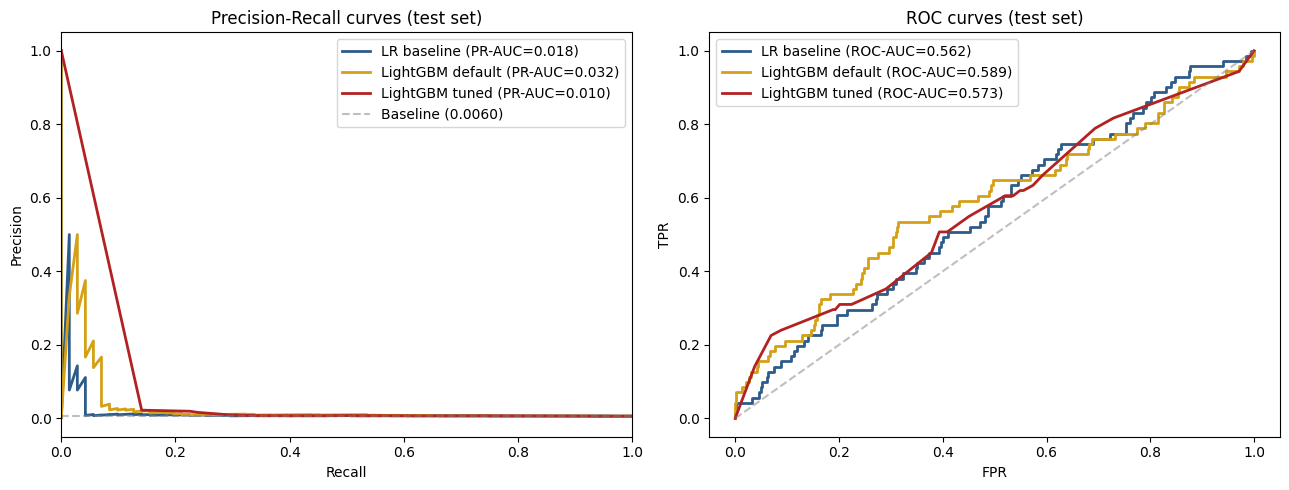

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for proba, name, color in [(lr_test_proba, 'LR baseline', '#2E5C8A'),
                            (lgb_test_proba_default, 'LightGBM default', '#D4A017'),
                            (lgb_test_proba, 'LightGBM tuned', '#B22222')]:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[0].plot(rec, prec, label=f"{name} (PR-AUC={average_precision_score(y_test, proba):.3f})", color=color, lw=2)
axes[0].axhline(y_test.mean(), color='gray', linestyle='--', alpha=0.5, label=f'Baseline ({y_test.mean():.4f})')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall curves (test set)'); axes[0].legend()
axes[0].set_xlim(0, 1)

for proba, name, color in [(lr_test_proba, 'LR baseline', '#2E5C8A'),
                            (lgb_test_proba_default, 'LightGBM default', '#D4A017'),
                            (lgb_test_proba, 'LightGBM tuned', '#B22222')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC-AUC={roc_auc_score(y_test, proba):.3f})", color=color, lw=2)
axes[1].plot([0,1],[0,1], color='gray', linestyle='--', alpha=0.5)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].set_title('ROC curves (test set)'); axes[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/model_comparison_v2.png", dpi=110, bbox_inches='tight')
plt.show()


## 8. P3.5 — SHAP

SHAP shape: (11834, 13)

Global SHAP feature importance (all features):
                      feature  mean_abs_shap
      rec_months_since_flight       0.207927
           mon_clv_asof_proxy       0.206982
           demo_tenure_months       0.177511
freq_flights_per_active_month       0.161528
       freq_months_active_6mo       0.044566
               Marital Status       0.042140
           trend_flights_diff       0.007873
             mon_redeem_ratio       0.000000
                       Gender       0.000000
                    Education       0.000000
                  Salary_Band       0.000000
                 Loyalty Card       0.000000
                     Province       0.000000


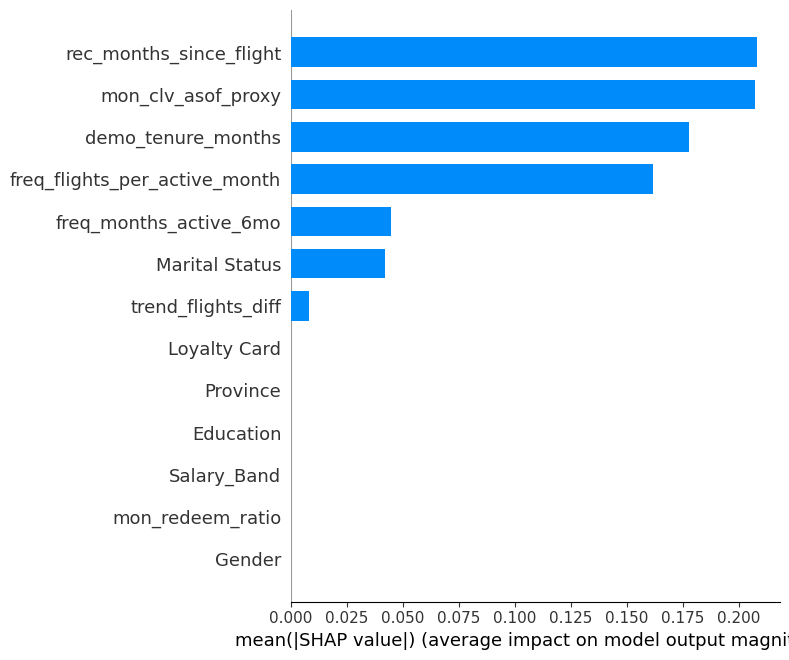

In [10]:
explainer = shap.TreeExplainer(lgb_best)
shap_values = explainer.shap_values(test_enc)
shap_arr = shap_values[1] if isinstance(shap_values, list) else shap_values
print(f"SHAP shape: {shap_arr.shape}")

global_imp = pd.DataFrame({
    'feature': test_enc.columns,
    'mean_abs_shap': np.abs(shap_arr).mean(axis=0),
}).sort_values('mean_abs_shap', ascending=False)
print("\nGlobal SHAP feature importance (all features):")
print(global_imp.to_string(index=False))
global_imp.to_csv(f"{OUT_DIR}/shap_global_importance_v2.csv", index=False)

fig = plt.figure(figsize=(10, 6))
shap.summary_plot(shap_arr, test_enc, plot_type='bar', max_display=15, show=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/shap_global_bar_v2.png", dpi=110, bbox_inches='tight')
plt.show()


## 9. P3.6 — K-means Segmentation (on lean features)

In [11]:
SEG_NUM = [c for c in NUM_COLS]   # all 7 numeric lean features
SEG_CAT = ['Loyalty Card', 'Salary_Band']
seg_input = test[['Loyalty Number'] + SEG_NUM + SEG_CAT].copy()

ohe = OneHotEncoder(drop='first', sparse_output=False)
seg_cat_arr = ohe.fit_transform(seg_input[SEG_CAT])
scaler = StandardScaler()
seg_num_arr = scaler.fit_transform(seg_input[SEG_NUM])
X_seg = np.hstack([seg_num_arr, seg_cat_arr])

K_RANGE = range(3, 9)
inertias, silhouettes = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_seg)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_seg, labels_k, sample_size=5000, random_state=42))
    print(f"K={k}: inertia={km.inertia_:.0f}, silhouette={silhouettes[-1]:.3f}")


K=3: inertia=71212, silhouette=0.136
K=4: inertia=65474, silhouette=0.125
K=5: inertia=60310, silhouette=0.135
K=6: inertia=56744, silhouette=0.128
K=7: inertia=54457, silhouette=0.118
K=8: inertia=52559, silhouette=0.109


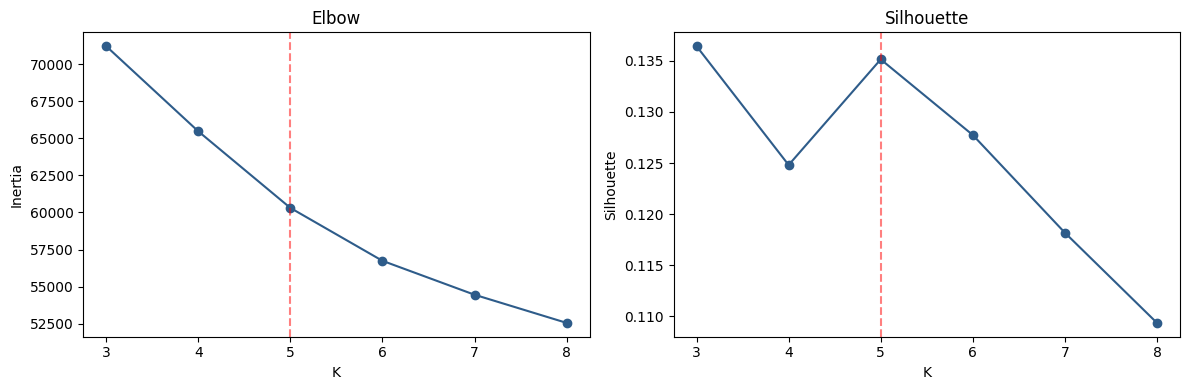

Davies-Bouldin: 1.798
Silhouette: 0.135

=== SEGMENT PROFILES ===
            n  churn_rate  avg_churn_proba  avg_recency  avg_months_active  avg_intensity  avg_trend  avg_redeem_ratio  avg_clv_proxy  avg_tenure
segment                                                                                                                                          
0         414       0.010            0.020        2.265              2.401          1.687      0.169             0.194      31752.234      42.811
1        3932       0.004            0.014        1.283              4.302          2.188      0.272             0.020      45538.138      50.436
2        1840       0.008            0.026        3.321              2.379          2.111     -2.457             0.013      33993.232      42.739
3        2815       0.006            0.017        1.109              3.640          3.172      5.205             0.015      48081.448      44.175
4        2833       0.008            0.018        1.358   

In [12]:
K_CHOSEN = 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_RANGE), inertias, marker='o', color='#2E5C8A'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia'); axes[0].set_title('Elbow'); axes[0].axvline(K_CHOSEN, color='red', linestyle='--', alpha=0.5)
axes[1].plot(list(K_RANGE), silhouettes, marker='o', color='#2E5C8A'); axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette'); axes[1].set_title('Silhouette'); axes[1].axvline(K_CHOSEN, color='red', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/segmentation_k_selection_v2.png", dpi=110, bbox_inches='tight')
plt.show()

km_final = KMeans(n_clusters=K_CHOSEN, random_state=42, n_init=20)
seg_labels = km_final.fit_predict(X_seg)
print(f"Davies-Bouldin: {davies_bouldin_score(X_seg, seg_labels):.3f}")
print(f"Silhouette: {silhouette_score(X_seg, seg_labels, sample_size=5000, random_state=42):.3f}")

seg_input['segment'] = seg_labels
seg_input['churn_proba'] = lgb_test_proba
seg_input['actual_churn'] = test['churned'].values
seg_input[['Loyalty Number','segment','churn_proba','actual_churn']].to_csv(f"{OUT_DIR}/segmentation_assignments_v2.csv", index=False)

profile = seg_input.groupby('segment').agg(
    n=('Loyalty Number', 'count'),
    churn_rate=('actual_churn', 'mean'),
    avg_churn_proba=('churn_proba', 'mean'),
    avg_recency=('rec_months_since_flight', 'mean'),
    avg_months_active=('freq_months_active_6mo', 'mean'),
    avg_intensity=('freq_flights_per_active_month', 'mean'),
    avg_trend=('trend_flights_diff', 'mean'),
    avg_redeem_ratio=('mon_redeem_ratio', 'mean'),
    avg_clv_proxy=('mon_clv_asof_proxy', 'mean'),
    avg_tenure=('demo_tenure_months', 'mean'),
).round(3)
profile.to_csv(f"{OUT_DIR}/segment_profiles_v2.csv")
print("\n=== SEGMENT PROFILES ===")
print(profile.to_string())

print("\nTier distribution per segment (%):")
print((pd.crosstab(seg_input['segment'], seg_input['Loyalty Card'], normalize='index') * 100).round(1))
print("\nSalary band distribution per segment (%):")
print((pd.crosstab(seg_input['segment'], seg_input['Salary_Band'], normalize='index') * 100).round(1))


## 10. Summary

In [13]:
print("="*68)
print("  PHASE 3 SUMMARY — LEAN FEATURE SET (v2)")
print("="*68)
print(f"\nBaseline churn rate (test set):        {y_test.mean()*100:.2f}%")
print(f"\nLR baseline       — PR-AUC: {lr_test_metrics['pr_auc']:.4f}  ROC-AUC: {lr_test_metrics['roc_auc']:.4f}  Lift@10%: {lr_test_metrics['lift_10']:.2f}x")
print(f"LightGBM default  — PR-AUC: {lgb_default_test_metrics['pr_auc']:.4f}  ROC-AUC: {lgb_default_test_metrics['roc_auc']:.4f}  Lift@10%: {lgb_default_test_metrics['lift_10']:.2f}x")
print(f"LightGBM tuned    — PR-AUC: {lgb_test_metrics['pr_auc']:.4f}  ROC-AUC: {lgb_test_metrics['roc_auc']:.4f}  Lift@10%: {lgb_test_metrics['lift_10']:.2f}x")
print(f"\nTop 5 global SHAP features (LEAN):")
for _, r in global_imp.head(5).iterrows():
    print(f"  {r['feature']:<35} {r['mean_abs_shap']:.4f}")
print(f"\nSegmentation: K={K_CHOSEN}, Davies-Bouldin: {davies_bouldin_score(X_seg, seg_labels):.3f}")


  PHASE 3 SUMMARY — LEAN FEATURE SET (v2)

Baseline churn rate (test set):        0.60%

LR baseline       — PR-AUC: 0.0179  ROC-AUC: 0.5619  Lift@10%: 1.55x
LightGBM default  — PR-AUC: 0.0318  ROC-AUC: 0.5889  Lift@10%: 2.11x
LightGBM tuned    — PR-AUC: 0.0103  ROC-AUC: 0.5732  Lift@10%: 2.68x

Top 5 global SHAP features (LEAN):
  rec_months_since_flight             0.2079
  mon_clv_asof_proxy                  0.2070
  demo_tenure_months                  0.1775
  freq_flights_per_active_month       0.1615
  freq_months_active_6mo              0.0446

Segmentation: K=5, Davies-Bouldin: 1.798
